## Project notebook

Exploratory Google Colab notebook: training cells modify weights when rerun. Read README before reproducing.


In [ ]:
!pip install torch torchvision
!pip install pandas


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [4]:
print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cu130
True


## Dataset

EMNIST Letters preprocessing with labels remapped from 1–26 to 0–25.


In [5]:
transform = transforms.ToTensor()
train_dataset = datasets.EMNIST(
    root="./data",
    split="letters",
    train=True,
    download=True,
    transform=transform,
    target_transform=lambda y: y - 1
)

test_dataset = datasets.EMNIST(
    root="./data",
    split="letters",
    train=False,
    download=True,
    transform=transform,
    target_transform=lambda y: y - 1
)

100%|██████████| 562M/562M [00:08<00:00, 65.9MB/s]


In [6]:
print("training samples:", len(train_dataset))
print("test samples:", len(test_dataset))
image,label= train_dataset[0]
print("Image shape:", image.shape)
print("Label:", label)
print("Pixel range:", image.min().item(), image.max().item())

training samples: 124800
test samples: 20800
Image shape: torch.Size([1, 28, 28])
Label: 22
Pixel range: 0.0 1.0


## Model architecture

Two convolutional blocks and a 26-way character classifier.


In [7]:
class CharacterCNN (nn.Module):
  def __init__(self):
    super().__init__()

    self.conv1=nn.Conv2d(1,32,padding=1, kernel_size=3)
    self.act1=nn.LeakyReLU(0.01)
    self.pool1=nn.MaxPool2d(2,2)

    self.conv2=nn.Conv2d(32,64,kernel_size=3,padding=1)
    self.act2=nn.LeakyReLU(0.01)
    self.pool2=nn.MaxPool2d(2,2)

    self.flatten=nn.Flatten()
    self.fc1=nn.Linear(3136,128)
    self.act3=nn.LeakyReLU(0.01)
    self.fc2=nn.Linear(128,26)

  def forward(self, x):
    x = self.pool1(self.act1(self.conv1(x)))
    x = self.pool2(self.act2(self.conv2(x)))

    x = self.flatten(x)

    x = self.act3(self.fc1(x))
    x = self.fc2(x)

    return x

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CharacterCNN().to(device)

dummy_input = torch.randn(1, 1, 28, 28).to(device)

output = model(dummy_input)

print("Output shape:", output.shape)
print(model)

Output shape: torch.Size([1, 26])
CharacterCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (act1): LeakyReLU(negative_slope=0.01)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (act2): LeakyReLU(negative_slope=0.01)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (act3): LeakyReLU(negative_slope=0.01)
  (fc2): Linear(in_features=128, out_features=26, bias=True)
)


## Training and validation split

Validation derives only from the official EMNIST training split; official test data is reserved.


In [9]:
from torch.utils.data import random_split, DataLoader

train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_data, val_data = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_dataset))

Training: 112320
Validation: 12480
Testing: 20800


In [10]:
train_loader = DataLoader(
    train_data,
    batch_size=128,
    shuffle=True
)
val_loader = DataLoader(
    val_data,
    batch_size=128,
    shuffle=False
)

In [11]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Minimum label:", labels.min().item())
print("Maximum label:", labels.max().item())

Images: torch.Size([128, 1, 28, 28])
Labels: torch.Size([128])
Minimum label: 0
Maximum label: 25


## Baseline training

One individual-batch training update followed by one full epoch. The baseline is frozen after training.


In [12]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

Loss function: CrossEntropyLoss()
Optimizer: Adam


In [13]:
model.train()

CharacterCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (act1): LeakyReLU(negative_slope=0.01)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (act2): LeakyReLU(negative_slope=0.01)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (act3): LeakyReLU(negative_slope=0.01)
  (fc2): Linear(in_features=128, out_features=26, bias=True)
)

In [14]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

optimizer.zero_grad()

outputs = model(images)

loss = criterion(outputs, labels)

loss.backward()

optimizer.step()

print("Training loss:", loss.item())

Training loss: 3.266180992126465


In [15]:
model.train()

running_loss = 0.0
correct = 0
total = 0

for images, labels in train_loader:

    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()

    optimizer.step()

    running_loss += loss.item() * images.size(0)

    predictions = outputs.argmax(dim=1)

    correct += (predictions == labels).sum().item()

    total += labels.size(0)

epoch_loss = running_loss / total
epoch_accuracy = 100 * correct / total

print("Training Loss:", epoch_loss)
print("Training Accuracy:", epoch_accuracy, "%")

Training Loss: 0.5370207104927455
Training Accuracy: 83.46331908831908 %


## Validation

Early evaluation on validation images; test set not used here.


In [16]:
model.eval()

CharacterCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (act1): LeakyReLU(negative_slope=0.01)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (act2): LeakyReLU(negative_slope=0.01)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (act3): LeakyReLU(negative_slope=0.01)
  (fc2): Linear(in_features=128, out_features=26, bias=True)
)

In [17]:
with torch.no_grad():
    images, labels = next(iter(val_loader))

    images = images.to(device)
    labels = labels.to(device)

    outputs = model(images)

    predictions = outputs.argmax(dim=1)

    accuracy = (predictions == labels).float().mean() * 100

    print("Batch Validation Accuracy:", accuracy.item(), "%")

Batch Validation Accuracy: 90.625 %


In [18]:
model.eval()

val_correct = 0
val_total = 0

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        val_correct += (predictions == labels).sum().item()
        val_total += labels.size(0)

val_accuracy = 100 * val_correct / val_total

print(f"Validation Accuracy: {val_accuracy:.2f}%")

Validation Accuracy: 90.92%


In [19]:
torch.save(
    model.state_dict(),
    "baseline_cnn.pth"
)

print("Baseline CNN saved successfully!")

Baseline CNN saved successfully!


## FGSM attack

White-box untargeted gradient-sign perturbation constrained in L-infinity.


In [20]:
import torch
import matplotlib.pyplot as plt

model.eval()

# FGSM Attack
def fgsm_attack(model, images, labels, epsilon):

    # Enable gradients for input images
    images = images.clone().detach().requires_grad_(True)

    # Forward pass
    outputs = model(images)

    # Calculate classification loss
    loss = criterion(outputs, labels)

    # Calculate gradients with respect to input images
    gradients = torch.autograd.grad(loss, images)[0]

    # FGSM perturbation
    perturbation = epsilon * gradients.sign()

    # Generate adversarial images
    adv_images = images + perturbation

    # Keep pixel values between 0 and 1
    adv_images = torch.clamp(adv_images, 0, 1)

    return adv_images.detach()


print("FGSM attack function!")

FGSM attack function!


## Perturbation sweep

Validation accuracy and attack success over FGSM epsilon values.


In [21]:
epsilons = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2]

results = []

for epsilon in epsilons:

    correct = 0
    total = 0
    originally_correct = 0
    successful_attacks = 0

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Predictions on clean images
        with torch.no_grad():
            clean_outputs = model(images)
            clean_preds = clean_outputs.argmax(dim=1)

        # Generate adversarial examples
        if epsilon == 0:
            adv_images = images
        else:
            adv_images = fgsm_attack(
                model,
                images,
                labels,
                epsilon
            )

        # Evaluate adversarial predictions
        with torch.no_grad():
            outputs = model(adv_images)
            predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        # Count attacks that fool previously correct predictions
        clean_correct = clean_preds == labels

        originally_correct += clean_correct.sum().item()

        successful_attacks += (
            clean_correct & (predictions != labels)
        ).sum().item()

    accuracy = 100 * correct / total

    attack_success_rate = (
        100 * successful_attacks / originally_correct
    )

    results.append(accuracy)

    print(
        f"Epsilon: {epsilon:.2f} | "
        f"Accuracy: {accuracy:.2f}% | "
        f"Attack Success: {attack_success_rate:.2f}%"
    )

Epsilon: 0.00 | Accuracy: 90.92% | Attack Success: 0.00%
Epsilon: 0.02 | Accuracy: 86.21% | Attack Success: 5.18%
Epsilon: 0.05 | Accuracy: 76.95% | Attack Success: 15.37%
Epsilon: 0.10 | Accuracy: 51.83% | Attack Success: 42.99%
Epsilon: 0.15 | Accuracy: 26.62% | Attack Success: 70.72%
Epsilon: 0.20 | Accuracy: 11.63% | Attack Success: 87.22%


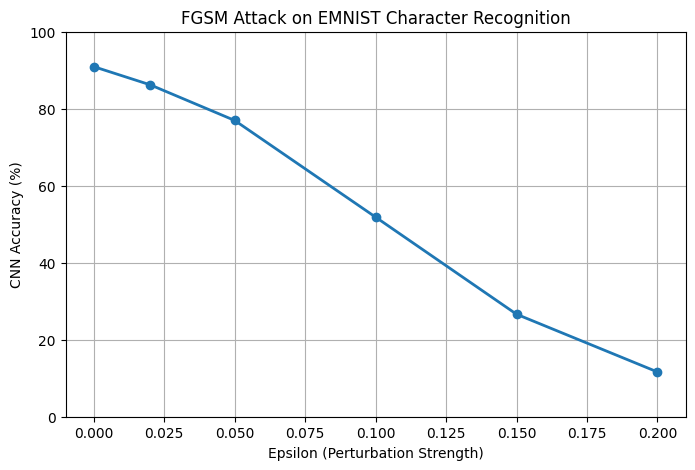

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    epsilons,
    results,
    marker="o",
    linewidth=2
)

plt.xlabel("Epsilon (Perturbation Strength)")
plt.ylabel("CNN Accuracy (%)")

plt.title("FGSM Attack on EMNIST Character Recognition")

plt.grid(True)
plt.ylim(0, 100)

plt.show()

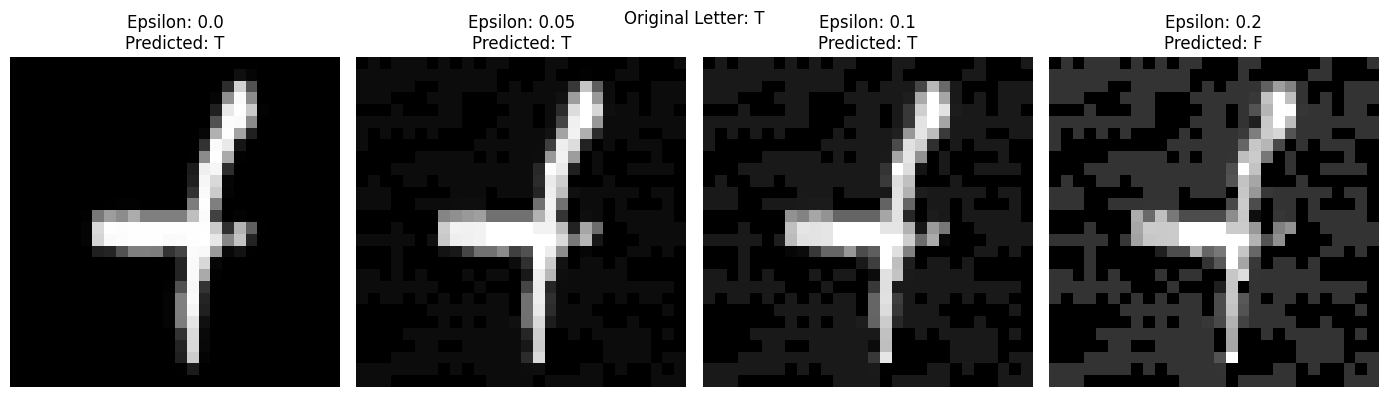

In [23]:
# Select one correctly classified validation image
model.eval()

for image, label in val_data:

    x = image.unsqueeze(0).to(device)
    y = torch.tensor([label], device=device)

    with torch.no_grad():
        prediction = model(x).argmax(dim=1).item()

    if prediction == label:
        break

epsilon_values = [0.0, 0.05, 0.1, 0.2]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for i, epsilon in enumerate(epsilon_values):

    if epsilon == 0:
        adv_image = x
    else:
        adv_image = fgsm_attack(
            model, x, y, epsilon
        )

    with torch.no_grad():
        pred = model(adv_image).argmax(dim=1).item()

    # EMNIST orientation correction for display
    display_image = adv_image.squeeze().cpu().numpy().T

    axes[i].imshow(display_image, cmap="gray")
    axes[i].set_title(
        f"Epsilon: {epsilon}\n"
        f"Predicted: {chr(65 + pred)}"
    )

    axes[i].axis("off")

plt.suptitle(f"Original Letter: {chr(65 + label)}")
plt.tight_layout()
plt.show()

## Class-wise susceptibility

FGSM attack success rates conditioned on initially correct examples.


In [24]:
import numpy as np

clean_correct = np.zeros(26, dtype=int)
attack_success = np.zeros(26, dtype=int)

epsilon = 0.1

In [25]:
model.eval()

for images, labels in val_loader:

    images = images.to(device)
    labels = labels.to(device)

    # Step 1: Original predictions
    with torch.no_grad():
        clean_outputs = model(images)
        clean_preds = clean_outputs.argmax(dim=1)

    # Step 2: Generate adversarial images
    adv_images = fgsm_attack(
        model, images, labels, epsilon
    )

    # Step 3: Predictions after attack
    with torch.no_grad():
        adv_outputs = model(adv_images)
        adv_preds = adv_outputs.argmax(dim=1)

    # Step 4: Identify successful attacks
    originally_correct = (clean_preds == labels)

    fooled = originally_correct & (adv_preds != labels)

    # Step 5: Count results for each letter
    for i in range(26):

        class_mask = (labels == i)

        clean_correct[i] += (
            originally_correct & class_mask
        ).sum().item()

        attack_success[i] += (
            fooled & class_mask
        ).sum().item()

print("Class-wise analysis completed!")

Class-wise analysis completed!


In [26]:
print("Originally correct images:", clean_correct.sum())

print("Successful attacks:", attack_success.sum())

Originally correct images: 11347
Successful attacks: 4878


In [27]:
asr_per_class = np.divide(
    attack_success,
    clean_correct,
    out=np.zeros(26, dtype=float),
    where=clean_correct != 0
) * 100

In [28]:
for i in range(26):
    letter = chr(65 + i)

    print(
        f"{letter}: {asr_per_class[i]:.2f}%"
    )

A: 65.03%
B: 28.38%
C: 43.76%
D: 26.97%
E: 60.22%
F: 25.17%
G: 49.75%
H: 52.61%
I: 69.41%
J: 27.15%
K: 37.37%
L: 75.76%
M: 10.38%
N: 62.94%
O: 76.38%
P: 45.43%
Q: 67.26%
R: 64.99%
S: 24.02%
T: 39.35%
U: 30.66%
V: 41.01%
W: 14.83%
X: 26.83%
Y: 61.40%
Z: 21.75%


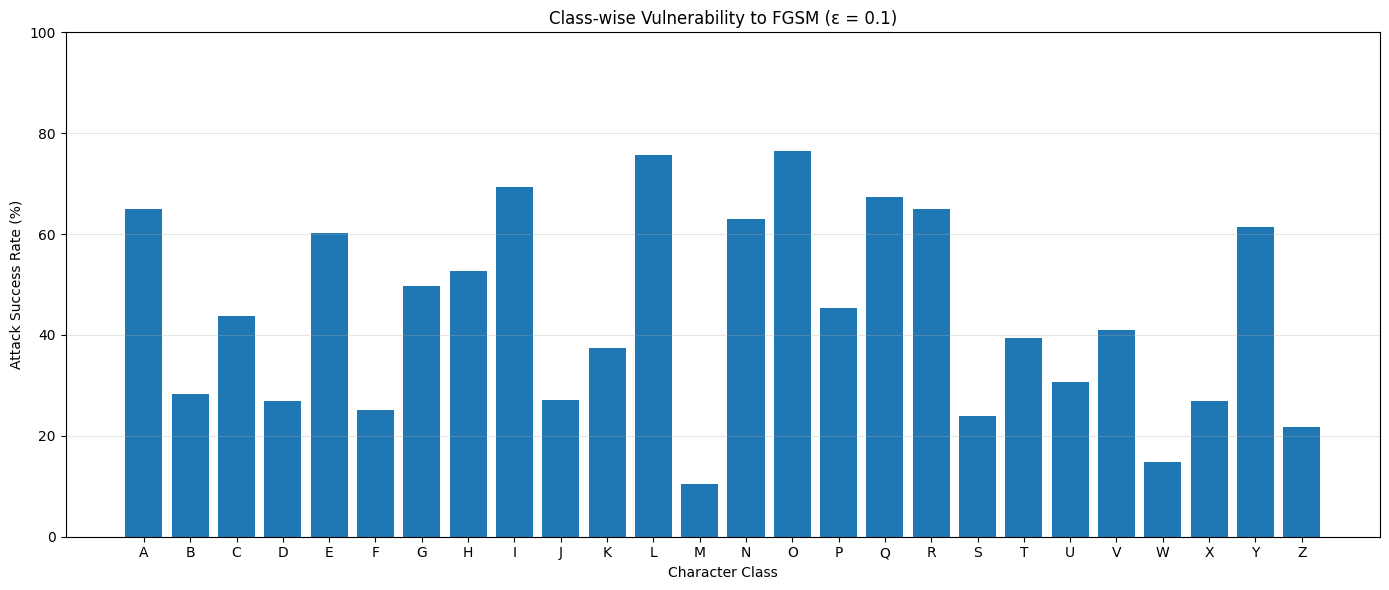

In [29]:
import matplotlib.pyplot as plt
import numpy as np

letters = [chr(65 + i) for i in range(26)]

plt.figure(figsize=(14, 6))

plt.bar(letters, asr_per_class)

plt.xlabel("Character Class")
plt.ylabel("Attack Success Rate (%)")

plt.title("Class-wise Vulnerability to FGSM (ε = 0.1)")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("classwise_fgsm_vulnerability.png", dpi=300)

plt.show()

## Defense: mixed clean/adversarial fine-tuning

Deep-copy of baseline, additional batch then one full epoch of 50/50 clean/adversarial CE.


In [30]:
import copy

defended_model = copy.deepcopy(model).to(device)

defense_optimizer = optim.Adam(
    defended_model.parameters(),
    lr=0.0001
)

print("Defense model created successfully!")

Defense model created successfully!


In [31]:
defended_model.train()

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

adv_images = fgsm_attack(
    defended_model,
    images,
    labels,
    epsilon=0.1
)

In [32]:
clean_outputs = defended_model(images)
adv_outputs = defended_model(adv_images)

clean_loss = criterion(clean_outputs, labels)
adv_loss = criterion(adv_outputs, labels)

total_loss = 0.5 * clean_loss + 0.5 * adv_loss

print("Clean Loss:", clean_loss.item())
print("Adversarial Loss:", adv_loss.item())
print("Combined Loss:", total_loss.item())

Clean Loss: 0.2977810502052307
Adversarial Loss: 1.481534719467163
Combined Loss: 0.8896578550338745


In [33]:
defense_optimizer.zero_grad()

total_loss.backward()

defense_optimizer.step()

print("Defense model updated successfully!")

Defense model updated successfully!


In [34]:
defended_model.train()

epochs = 1

for epoch in range(epochs):

    running_clean_loss = 0.0
    running_adv_loss = 0.0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Generate adversarial examples
        adv_images = fgsm_attack(
            defended_model,
            images,
            labels,
            epsilon=0.1
        )

        # Clear previous gradients
        defense_optimizer.zero_grad()

        # Forward propagation
        clean_outputs = defended_model(images)
        adv_outputs = defended_model(adv_images)

        # Calculate losses
        clean_loss = criterion(clean_outputs, labels)
        adv_loss = criterion(adv_outputs, labels)

        # Combined loss
        total_loss = 0.5 * clean_loss + 0.5 * adv_loss

        # Backpropagation
        total_loss.backward()

        # Update model weights
        defense_optimizer.step()

        # Track losses
        batch_size = images.size(0)

        running_clean_loss += clean_loss.item() * batch_size
        running_adv_loss += adv_loss.item() * batch_size

        total += batch_size

    print(f"Epoch {epoch + 1}")
    print(f"Clean Loss: {running_clean_loss / total:.4f}")
    print(f"Adversarial Loss: {running_adv_loss / total:.4f}")

Epoch 1
Clean Loss: 0.2410
Adversarial Loss: 0.9042


## Validation comparison

Separate FGSM attacks generated for each model, not transfer attacks.


In [35]:
def evaluate_robustness(model, loader, epsilon=0.1):

    model.eval()

    clean_correct = 0
    adv_correct = 0
    successful_attacks = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Evaluate clean images
        with torch.no_grad():
            clean_outputs = model(images)
            clean_preds = clean_outputs.argmax(dim=1)

        # Generate FGSM attacks against this model
        adv_images = fgsm_attack(
            model, images, labels, epsilon
        )

        # Evaluate adversarial images
        with torch.no_grad():
            adv_outputs = model(adv_images)
            adv_preds = adv_outputs.argmax(dim=1)

        clean_correct += (clean_preds == labels).sum().item()
        adv_correct += (adv_preds == labels).sum().item()

        successful_attacks += (
            (clean_preds == labels) &
            (adv_preds != labels)
        ).sum().item()

        total += labels.size(0)

    clean_accuracy = 100 * clean_correct / total

    adv_accuracy = 100 * adv_correct / total

    attack_success_rate = (
        100 * successful_attacks / clean_correct
        if clean_correct > 0 else 0
    )

    return clean_accuracy, adv_accuracy, attack_success_rate

In [36]:
baseline_results = evaluate_robustness(
    model, val_loader, epsilon=0.1
)

defended_results = evaluate_robustness(
    defended_model, val_loader, epsilon=0.1
)

print("BASELINE CNN")
print(f"Clean Accuracy: {baseline_results[0]:.2f}%")
print(f"FGSM Accuracy: {baseline_results[1]:.2f}%")
print(f"Attack Success Rate: {baseline_results[2]:.2f}%")

print("\nDEFENDED CNN")
print(f"Clean Accuracy: {defended_results[0]:.2f}%")
print(f"FGSM Accuracy: {defended_results[1]:.2f}%")
print(f"Attack Success Rate: {defended_results[2]:.2f}%")

BASELINE CNN
Clean Accuracy: 90.92%
FGSM Accuracy: 51.83%
Attack Success Rate: 42.99%

DEFENDED CNN
Clean Accuracy: 92.11%
FGSM Accuracy: 72.34%
Attack Success Rate: 21.46%


In [37]:
torch.save(
    defended_model.state_dict(),
    "defended_cnn.pth"
)

print("Defended CNN saved successfully!")

Defended CNN saved successfully!


In [ ]:
from google.colab import files

files.download("baseline_cnn.pth")
files.download("defended_cnn.pth")

## Projected gradient descent

Initial PGD with ten gradient steps, validation only.


In [39]:
def pgd_attack(model, images, labels, epsilon=0.1, alpha=0.02, steps=10):

    original_images = images.clone().detach()

    adv_images = original_images.clone()

    for step in range(steps):

        adv_images.requires_grad_(True)

        outputs = model(adv_images)

        loss = criterion(outputs, labels)

        gradients = torch.autograd.grad(
            loss, adv_images
        )[0]

        # Take a small gradient ascent step
        adv_images = adv_images + alpha * gradients.sign()

        # Project into the allowed epsilon range
        perturbation = torch.clamp(
            adv_images - original_images,
            min=-epsilon,
            max=epsilon
        )

        adv_images = original_images + perturbation

        # Ensure valid pixel values
        adv_images = torch.clamp(adv_images, 0, 1).detach()

    return adv_images

In [40]:
model.eval()

images, labels = next(iter(val_loader))

images = images.to(device)
labels = labels.to(device)

adv_images = pgd_attack(
    model,
    images,
    labels,
    epsilon=0.1,
    alpha=0.02,
    steps=10
)

print("Original shape:", images.shape)
print("Adversarial shape:", adv_images.shape)

max_difference = (adv_images - images).abs().max().item()

print("Maximum pixel difference:", max_difference)

Original shape: torch.Size([128, 1, 28, 28])
Adversarial shape: torch.Size([128, 1, 28, 28])
Maximum pixel difference: 0.10000002384185791


In [41]:
def compare_attacks(model, loader):

    model.eval()

    clean_correct = 0
    fgsm_correct = 0
    pgd_correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Normal prediction
        with torch.no_grad():
            clean_preds = model(images).argmax(dim=1)

        # FGSM attack
        fgsm_images = fgsm_attack(
            model, images, labels, epsilon=0.1
        )

        # PGD attack
        pgd_images = pgd_attack(
            model,
            images,
            labels,
            epsilon=0.1,
            alpha=0.02,
            steps=10
        )

        # Evaluate both attacks
        with torch.no_grad():

            fgsm_preds = model(fgsm_images).argmax(dim=1)

            pgd_preds = model(pgd_images).argmax(dim=1)

        clean_correct += (clean_preds == labels).sum().item()

        fgsm_correct += (fgsm_preds == labels).sum().item()

        pgd_correct += (pgd_preds == labels).sum().item()

        total += labels.size(0)

    return {
        "Clean": 100 * clean_correct / total,
        "FGSM": 100 * fgsm_correct / total,
        "PGD": 100 * pgd_correct / total
    }

In [42]:
baseline_attack_results = compare_attacks(
    model,
    val_loader
)

defended_attack_results = compare_attacks(
    defended_model,
    val_loader
)

print("BASELINE CNN")
for attack, accuracy in baseline_attack_results.items():
    print(f"{attack}: {accuracy:.2f}%")

print("\nDEFENDED CNN")
for attack, accuracy in defended_attack_results.items():
    print(f"{attack}: {accuracy:.2f}%")

BASELINE CNN
Clean: 90.92%
FGSM: 51.83%
PGD: 34.53%

DEFENDED CNN
Clean: 92.11%
FGSM: 72.34%
PGD: 64.27%


## Held-out final evaluation

Official 20,800-image EMNIST test partition.


In [43]:
test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))

Test images: 20800
Test batches: 163


## PGD with random restarts

40 steps, epsilon 0.1, alpha 0.01, three random starts and per-image best loss.


In [44]:
import torch
import torch.nn.functional as F

def strong_pgd_attack(
    model,
    images,
    labels,
    epsilon=0.1,
    alpha=0.01,
    steps=40,
    restarts=3
):

    original = images.detach()

    best_adv = original.clone()

    best_loss = torch.full(
        (images.size(0),),
        -float("inf"),
        device=images.device
    )

    for restart in range(restarts):

        # Random initialization
        delta = torch.empty_like(original).uniform_(
            -epsilon, epsilon
        )

        adv = torch.clamp(original + delta, 0, 1).detach()

        for step in range(steps):

            adv.requires_grad_(True)

            outputs = model(adv)

            loss = F.cross_entropy(outputs, labels)

            gradients = torch.autograd.grad(
                loss, adv
            )[0]

            # Gradient ascent
            adv = adv.detach() + alpha * gradients.sign()

            # Project into epsilon constraint
            delta = torch.clamp(
                adv - original,
                -epsilon,
                epsilon
            )

            adv = torch.clamp(
                original + delta,
                0,
                1
            ).detach()

        # Evaluate this restart
        with torch.no_grad():

            outputs = model(adv)

            losses = F.cross_entropy(
                outputs,
                labels,
                reduction="none"
            )

            better = losses > best_loss

            best_loss = torch.where(
                better,
                losses,
                best_loss
            )

            best_adv = torch.where(
                better[:, None, None, None],
                adv,
                best_adv
            )

    return best_adv.detach()

In [45]:
def final_evaluation(model, loader):

    model.eval()

    total = 0

    clean_correct = 0
    fgsm_correct = 0
    pgd_correct = 0

    fgsm_success = 0
    pgd_success = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clean predictions
        with torch.no_grad():
            clean_preds = model(images).argmax(dim=1)

        # FGSM attack
        fgsm_images = fgsm_attack(
            model,
            images,
            labels,
            epsilon=0.1
        )

        # Stronger PGD attack
        pgd_images = strong_pgd_attack(
            model,
            images,
            labels,
            epsilon=0.1,
            alpha=0.01,
            steps=40,
            restarts=3
        )

        # Evaluate adversarial images
        with torch.no_grad():

            fgsm_preds = model(fgsm_images).argmax(dim=1)

            pgd_preds = model(pgd_images).argmax(dim=1)

        clean_mask = clean_preds == labels

        clean_correct += clean_mask.sum().item()

        fgsm_correct += (
            fgsm_preds == labels
        ).sum().item()

        pgd_correct += (
            pgd_preds == labels
        ).sum().item()

        fgsm_success += (
            clean_mask & (fgsm_preds != labels)
        ).sum().item()

        pgd_success += (
            clean_mask & (pgd_preds != labels)
        ).sum().item()

        total += labels.size(0)

    return {
        "Clean Accuracy": 100 * clean_correct / total,

        "FGSM Accuracy": 100 * fgsm_correct / total,

        "PGD Accuracy": 100 * pgd_correct / total,

        "FGSM ASR": 100 * fgsm_success / clean_correct,

        "PGD ASR": 100 * pgd_success / clean_correct
    }

In [46]:
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

## Final experimental results

Reported values reflect this Colab execution; training seed not fully fixed.


In [47]:
print("Evaluating Baseline CNN...")

baseline_final = final_evaluation(
    model,
    test_loader
)

print("Baseline evaluation completed!")

print("\nEvaluating Defended CNN...")

defended_final = final_evaluation(
    defended_model,
    test_loader
)

print("Defense evaluation completed!")

Evaluating Baseline CNN...
Baseline evaluation completed!

Evaluating Defended CNN...
Defense evaluation completed!


In [48]:
import pandas as pd

results_df = pd.DataFrame({
    "Metric": list(baseline_final.keys()),
    "Baseline CNN": list(baseline_final.values()),
    "Defended CNN": list(defended_final.values())
})

print("\nFINAL ADVERSARIAL ROBUSTNESS RESULTS")

print(results_df.round(2).to_string(index=False))


FINAL ADVERSARIAL ROBUSTNESS RESULTS
        Metric  Baseline CNN  Defended CNN
Clean Accuracy         90.72         91.93
 FGSM Accuracy         52.51         72.33
  PGD Accuracy         32.30         62.50
      FGSM ASR         42.12         21.32
       PGD ASR         64.39         32.01
